# RoadSight Rwanda
## Road Accident Risk Analysis
## Group D — Big Data Project 2026

**Thematic area:** Public Safety  
**Research question:** What patterns are associated with road accidents, and can available data predict accident severity or risk?

---
### Dataset notice
> ⚠️ The dataset used (`rwanda_road_crashes_SYNTHETIC.csv`) is **synthetic/simulated** — clearly labeled in the `data_source` column. It was generated for educational purposes and is not real police or government data. All findings are illustrative.

### Objectives
1. Investigate accident patterns by location, time, and road conditions.
2. Clean and explore the road-safety dataset.
3. Develop and evaluate a severity classification model.
4. Build an interactive dashboard communicating risk patterns.

## 1. Setup

In [1]:
import warnings, json, pickle
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import plotly.express as px
import plotly.graph_objects as go

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
%matplotlib inline

BASE = Path(__file__).parent.parent if '__file__' in dir() else Path('.').resolve().parent
RAW  = BASE / 'data' / 'raw'       / 'rwanda_road_crashes_SYNTHETIC.csv'
PROC = BASE / 'data' / 'processed' / 'accidents_clean.csv'
FIGS = BASE / 'outputs' / 'figures'
MODELS = BASE / 'outputs' / 'models'

SEV_ORDER  = ['Damage only', 'Minor injury', 'Serious/grievous', 'Fatal']
SEV_COLORS = {'Damage only':'#4CAF50','Minor injury':'#FF9800','Serious/grievous':'#FF5722','Fatal':'#9C27B0'}
print('Setup complete.')

Setup complete.


## 2. Data Cleaning

Full cleaning is in `scripts/clean_data.py`. The cleaning log is at `report/cleaning_log.md`.  
Here we load the cleaned dataset and review the key steps taken.

In [2]:
# Show the cleaning log
log_path = BASE / 'report' / 'cleaning_log.md'
print(log_path.read_text())

## Cleaning Log — Rwanda Road Accident Dataset

### Source
File: `rwanda_road_crashes_SYNTHETIC.csv`  
Data is **synthetic/simulated** (not real police records). Clearly labeled in `data_source` column.

### 1. Load
Initial shape: **3030 rows × 27 columns**

### 2. Removed Columns
- Dropped `data_source`: constant metadata column, not useful for analysis.

### 3. Datetime Parsing
- Parsed `crash_datetime` to datetime type.
- Extracted `crash_year`, `crash_month`, `crash_hour`, `crash_dow`, `crash_dow_name`.
- Added `is_weekend` binary flag.
- Added `time_of_day` categorical bin (Night/Morning/Afternoon/Evening/Late evening).

### 4. Case Normalisation
- `vehicle_primary` and `other_party`: standardised to Title Case (e.g. 'CAR' → 'Car', 'motorcycle' → 'Motorcycle').

### 5. Driver Age
- Replaced **5** implausible values (age < 15 or > 100) with NaN.

### 6. Missing Target
- Dropped **23** rows with missing `severity` (target variable).

### 7. Missing Categoricals → 'Unknown'
- `road_c

In [3]:
df = pd.read_csv(PROC)
df['crash_datetime'] = pd.to_datetime(df['crash_datetime'])
print(f'Loaded cleaned dataset: {df.shape[0]:,} rows × {df.shape[1]} columns')
df.head(3)

Loaded cleaned dataset: 3,007 rows × 35 columns


,crash_id,crash_datetime,province,district,sector,street_or_road,latitude,longitude,road_class,speed_limit_kmh,...,persons_injured,crash_year,crash_month,crash_hour,crash_dow,crash_dow_name,is_weekend,time_of_day,age_group,severity_code
0,SYN-01807,2022-01-15 01:19:00,Kigali City,Kicukiro,Kagarama,KN 3 Rd,-1.99557,30.11161,Main road,50,...,0,2022,1,1,5,Saturday,1,Night,35–44,0
1,SYN-02734,2024-05-08 20:31:00,Kigali City,Nyarugenge,Muhima,KN 2 St,-1.93521,30.05448,Urban street,40,...,0,2024,5,20,2,Wednesday,0,Evening,≤24,0
2,SYN-00270,2023-02-24 20:14:00,Kigali City,Kicukiro,Gikondo,KG 7 Ave,-1.97050,30.06805,Main road,50,...,1,2023,2,20,4,Friday,0,Evening,25–34,1


In [4]:
print('--- Missing values in cleaned data ---')
print(df.isnull().sum()[df.isnull().sum() > 0])
print('\n--- Data types ---')
print(df.dtypes)

--- Missing values in cleaned data ---
Series([], dtype: int64)

--- Data types ---
crash_id                         str
crash_datetime        datetime64[us]
province                         str
district                         str
sector                           str
street_or_road                   str
latitude                     float64
longitude                    float64
road_class                       str
speed_limit_kmh                int64
road_surface                     str
road_condition                   str
junction                         str
weather                          str
lighting                         str
vehicle_primary                  str
other_party                      str
vehicles_involved              int64
driver_age                     int64
driver_gender                    str
alcohol_suspected                str
speeding_suspected               str
helmet_worn                      str
severity                         str
persons_killed              

In [5]:
print('--- Descriptive statistics (numeric) ---')
df[['speed_limit_kmh','vehicles_involved','driver_age','persons_killed','persons_injured','severity_code']].describe().round(2)

--- Descriptive statistics (numeric) ---


,speed_limit_kmh,vehicles_involved,driver_age,persons_killed,persons_injured,severity_code
count,3007.00,3007.00,3007.00,3007.00,3007.00,3007.00
mean,50.62,1.96,35.40,0.11,0.86,0.82
std,11.60,0.65,10.09,0.46,0.93,0.91
min,40.00,1.00,18.00,0.00,0.00,0.00
25%,40.00,2.00,29.00,0.00,0.00,0.00
50%,50.00,2.00,35.00,0.00,1.00,1.00
75%,60.00,2.00,42.00,0.00,2.00,1.00
max,80.00,3.00,99.00,3.00,3.00,3.00


## 3. Exploratory Data Analysis

### 3.1 Severity Distribution & Class Balance

Severity counts:
severity
Damage only         1350
Minor injury        1051
Serious/grievous     400
Fatal                206

Class balance — Damage only : Fatal ratio = 6.6:1


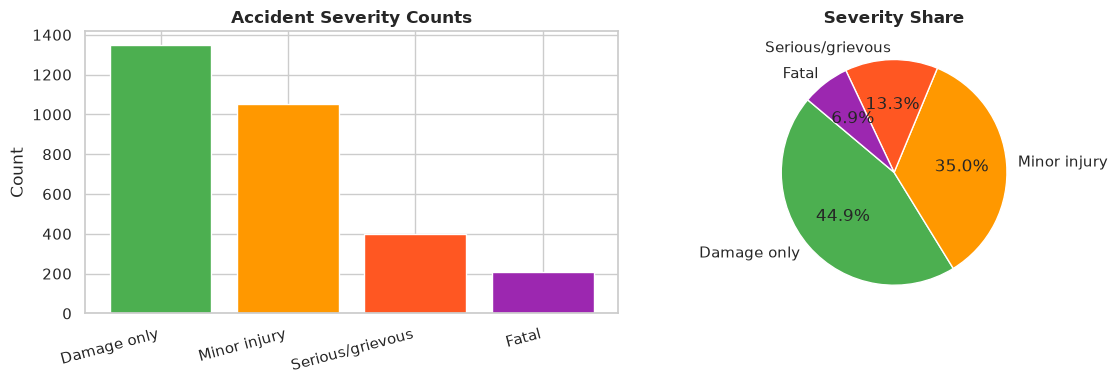

In [6]:
sev_counts = df['severity'].value_counts().reindex(SEV_ORDER)
print('Severity counts:')
print(sev_counts.to_string())
print(f'\nClass balance — Damage only : Fatal ratio = {sev_counts["Damage only"]/sev_counts["Fatal"]:.1f}:1')

fig, axes = plt.subplots(1,2, figsize=(12,4))
colors = [SEV_COLORS[s] for s in SEV_ORDER]
axes[0].bar(SEV_ORDER, sev_counts.values, color=colors, edgecolor='white')
axes[0].set_title('Accident Severity Counts', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_xticklabels(SEV_ORDER, rotation=15, ha='right')
pcts = sev_counts / sev_counts.sum() * 100
axes[1].pie(pcts, labels=SEV_ORDER, autopct='%1.1f%%', colors=colors, startangle=140)
axes[1].set_title('Severity Share', fontweight='bold')
plt.tight_layout()
plt.show()

### 3.2 Temporal Patterns

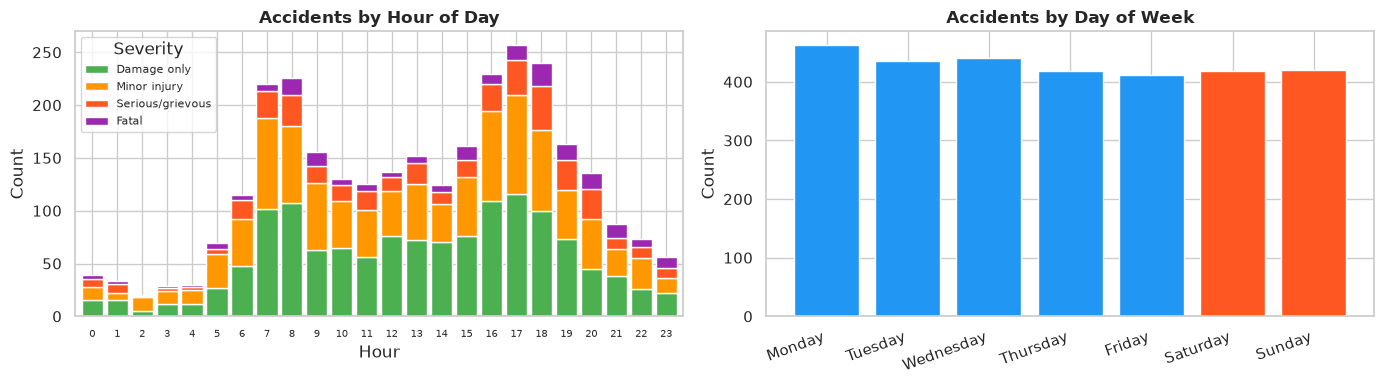

In [7]:
fig, axes = plt.subplots(1,2, figsize=(14,4))

# Hourly
hourly = df.groupby('crash_hour')['severity'].value_counts().unstack(fill_value=0).reindex(columns=SEV_ORDER, fill_value=0)
hourly.plot(kind='bar', ax=axes[0], color=colors, stacked=True, edgecolor='white', width=0.85)
axes[0].set_title('Accidents by Hour of Day', fontweight='bold')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Count')
axes[0].legend(title='Severity', fontsize=8)
axes[0].set_xticklabels([str(h) for h in range(24)], rotation=0, fontsize=7)

# Day of week
dow_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
dow_counts = df['crash_dow_name'].value_counts().reindex(dow_order)
bar_colors2 = ['#FF5722' if d in ['Saturday','Sunday'] else '#2196F3' for d in dow_order]
axes[1].bar(dow_order, dow_counts.values, color=bar_colors2, edgecolor='white')
axes[1].set_title('Accidents by Day of Week', fontweight='bold')
axes[1].set_ylabel('Count')
axes[1].set_xticklabels(dow_order, rotation=20, ha='right')
plt.tight_layout()
plt.show()

### 3.3 Geographic & Road Context

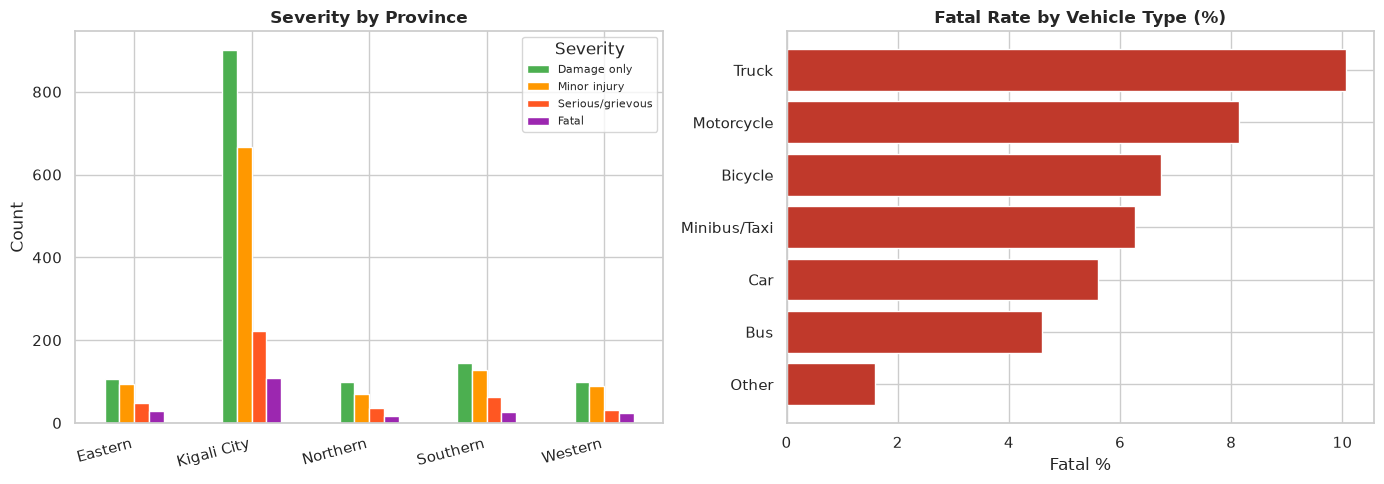

In [8]:
fig, axes = plt.subplots(1,2, figsize=(14,5))

prov_sev = df.groupby(['province','severity']).size().unstack(fill_value=0).reindex(columns=SEV_ORDER, fill_value=0)
prov_sev.plot(kind='bar', ax=axes[0], color=colors, stacked=False, edgecolor='white')
axes[0].set_title('Severity by Province', fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Count')
axes[0].set_xticklabels(prov_sev.index, rotation=15, ha='right')
axes[0].legend(title='Severity', fontsize=8)

veh_fatal = df.groupby('vehicle_primary').apply(lambda g: (g['severity']=='Fatal').mean()*100).sort_values(ascending=True).tail(7)
axes[1].barh(veh_fatal.index, veh_fatal.values, color='#c0392b')
axes[1].set_title('Fatal Rate by Vehicle Type (%)', fontweight='bold')
axes[1].set_xlabel('Fatal %')
plt.tight_layout()
plt.show()

### 3.4 Risk Factors: Weather, Alcohol, Speeding, Lighting

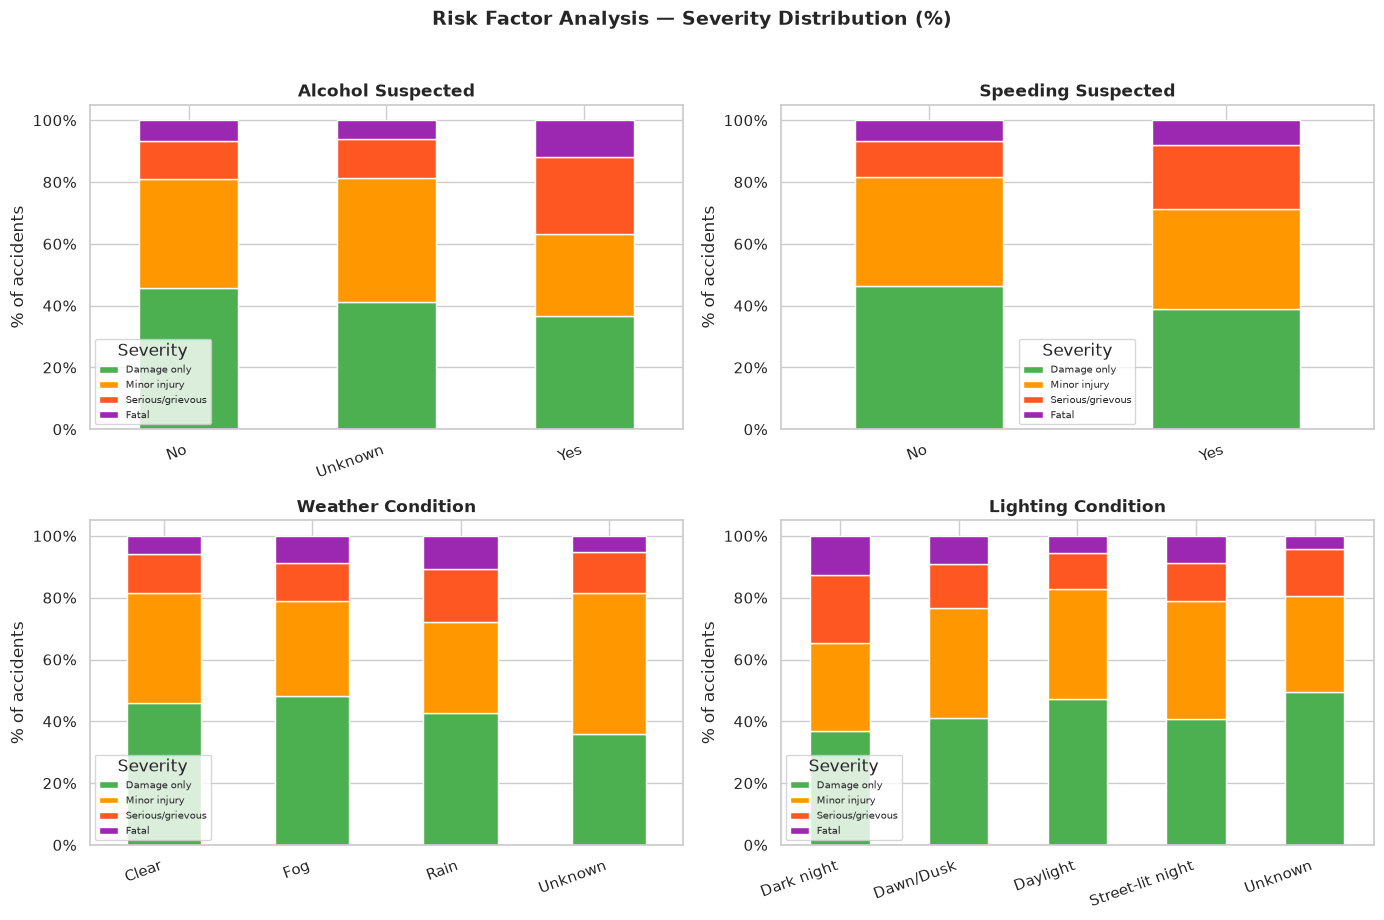

In [9]:
fig, axes = plt.subplots(2,2, figsize=(14,9))

for ax, col, title in [
    (axes[0,0], 'alcohol_suspected', 'Alcohol Suspected'),
    (axes[0,1], 'speeding_suspected', 'Speeding Suspected'),
    (axes[1,0], 'weather',           'Weather Condition'),
    (axes[1,1], 'lighting',          'Lighting Condition'),
]:
    ct = df.groupby([col,'severity']).size().unstack(fill_value=0).reindex(columns=SEV_ORDER, fill_value=0)
    ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
    ct_pct.plot(kind='bar', ax=ax, color=colors, stacked=True, edgecolor='white')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('% of accidents')
    ax.set_xticklabels(ct.index, rotation=20, ha='right')
    ax.legend(title='Severity', fontsize=7)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter())

plt.suptitle('Risk Factor Analysis — Severity Distribution (%)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 3.5 Correlation Matrix

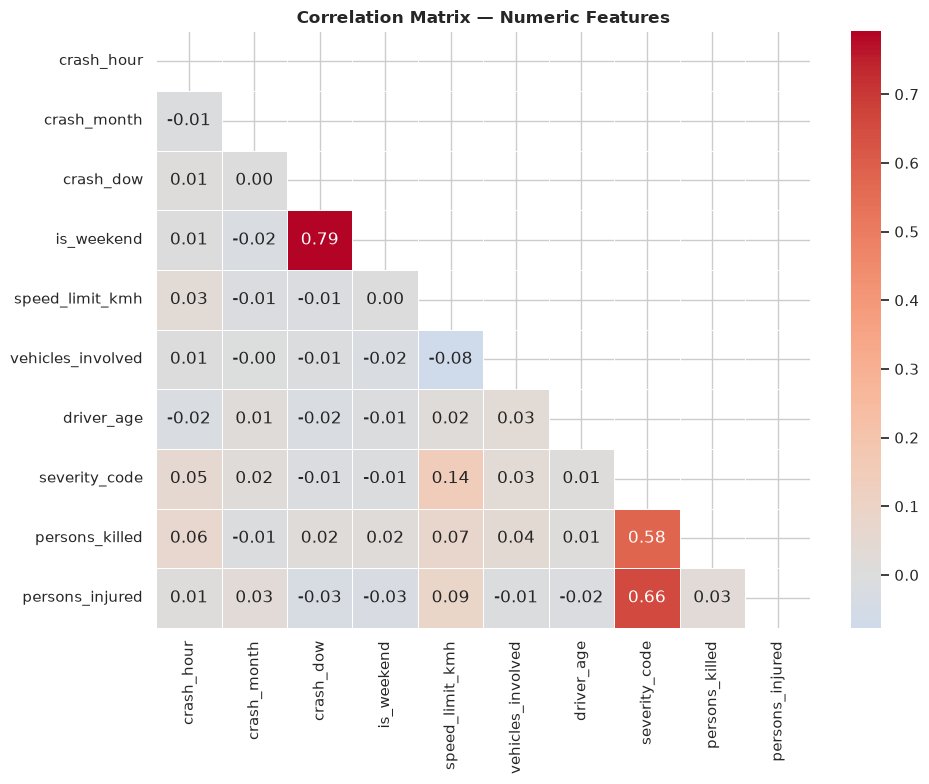

In [10]:
num_cols = ['crash_hour','crash_month','crash_dow','is_weekend',
            'speed_limit_kmh','vehicles_involved','driver_age',
            'severity_code','persons_killed','persons_injured']
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(10,8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax, linewidths=0.5)
ax.set_title('Correlation Matrix — Numeric Features', fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Machine Learning Model — Severity Classification

**Task:** Classify accident severity into four classes: Damage only, Minor injury, Serious/grievous, Fatal.  
**Challenge:** Severe class imbalance (Fatal = 6.8% of records). Addressed with SMOTE on the training set only.  
**Models trained:** Random Forest (200 trees) and XGBoost (300 estimators).

In [11]:
FEATURES = [
    'crash_hour','crash_month','crash_dow','is_weekend',
    'speed_limit_kmh','vehicles_involved','driver_age',
    'road_class','road_surface','road_condition','junction',
    'weather','lighting','vehicle_primary',
    'alcohol_suspected','speeding_suspected','driver_gender',
    'helmet_worn','province','time_of_day','age_group',
]
TARGET = 'severity'

df_model = df[FEATURES + [TARGET]].copy()

# Encode
label_encoders = {}
cat_cols = df_model.select_dtypes(include=['object','category']).columns.tolist()
cat_cols = [c for c in cat_cols if c != TARGET]
for col in cat_cols:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col].astype(str))
    label_encoders[col] = le

target_le = LabelEncoder()
target_le.fit(['Damage only','Minor injury','Serious/grievous','Fatal'])
df_model[TARGET] = target_le.transform(df_model[TARGET])

X = df_model[FEATURES]
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print('Training set size after SMOTE:', len(X_train_sm))
print('Test set size:', len(X_test))

Training set size after SMOTE: 4320
Test set size: 602


=== Random Forest Classification Report ===
                  precision    recall  f1-score   support

     Damage only       0.51      0.54      0.52       270
           Fatal       0.15      0.15      0.15        41
    Minor injury       0.38      0.37      0.38       211
Serious/grievous       0.25      0.23      0.24        80

        accuracy                           0.41       602
       macro avg       0.32      0.32      0.32       602
    weighted avg       0.41      0.41      0.41       602



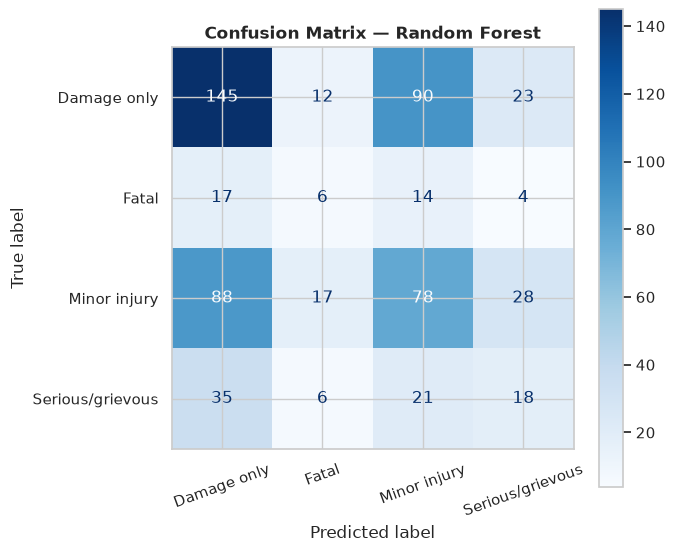

In [12]:
rf = RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train_sm, y_train_sm)
y_pred_rf = rf.predict(X_test)

print('=== Random Forest Classification Report ===')
print(classification_report(y_test, y_pred_rf, target_names=target_le.classes_))

fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_rf), display_labels=target_le.classes_).plot(ax=ax, cmap='Blues', xticks_rotation=20)
ax.set_title('Confusion Matrix — Random Forest', fontweight='bold')
plt.tight_layout()
plt.show()

=== XGBoost Classification Report ===
                  precision    recall  f1-score   support

     Damage only       0.48      0.49      0.49       270
           Fatal       0.10      0.10      0.10        41
    Minor injury       0.37      0.37      0.37       211
Serious/grievous       0.11      0.10      0.11        80

        accuracy                           0.37       602
       macro avg       0.26      0.26      0.26       602
    weighted avg       0.37      0.37      0.37       602



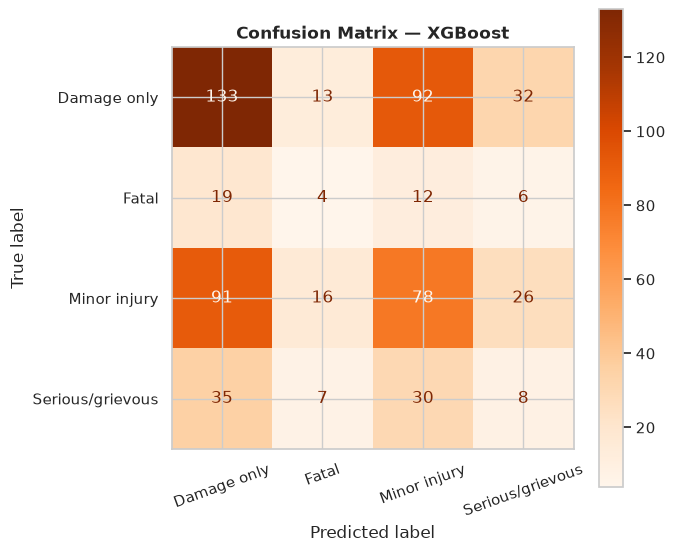

In [13]:
xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                    eval_metric='mlogloss', random_state=42, n_jobs=-1)
xgb.fit(X_train_sm, y_train_sm)
y_pred_xgb = xgb.predict(X_test)

print('=== XGBoost Classification Report ===')
print(classification_report(y_test, y_pred_xgb, target_names=target_le.classes_))

fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_xgb), display_labels=target_le.classes_).plot(ax=ax, cmap='Oranges', xticks_rotation=20)
ax.set_title('Confusion Matrix — XGBoost', fontweight='bold')
plt.tight_layout()
plt.show()

Random Forest macro F1: 0.3202
XGBoost       macro F1: 0.2646


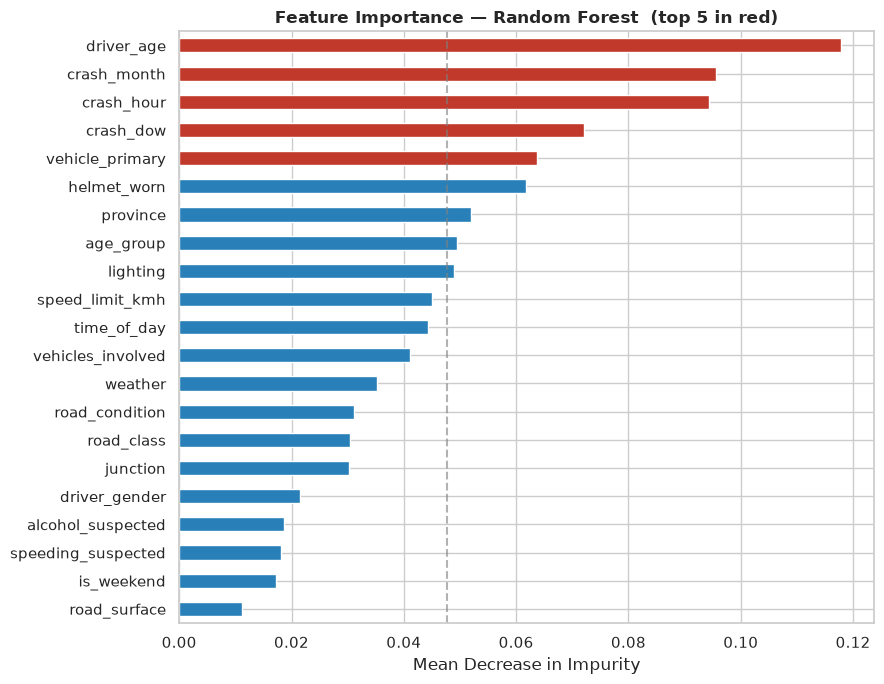

In [14]:
print(f'Random Forest macro F1: {f1_score(y_test, y_pred_rf,  average="macro"):.4f}')
print(f'XGBoost       macro F1: {f1_score(y_test, y_pred_xgb, average="macro"):.4f}')

importances = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(9,7))
bar_colors = ['#c0392b' if i >= len(importances)-5 else '#2980b9' for i in range(len(importances))]
importances.plot(kind='barh', ax=ax, color=bar_colors)
ax.set_title('Feature Importance — Random Forest  (top 5 in red)', fontweight='bold')
ax.set_xlabel('Mean Decrease in Impurity')
ax.axvline(importances.mean(), color='gray', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 5. Interactive Dashboard

In [15]:
from IPython.display import IFrame
dash_path = BASE / 'dashboard' / 'accident_risk_dashboard.html'
print(f'Dashboard located at: {dash_path.resolve()}')
# To view inline in Jupyter:
IFrame(str(dash_path), width='100%', height=800)

Dashboard located at: /projects/Big_Data/Project/rwanda_accident_analysis/dashboard/accident_risk_dashboard.html


## 6. Key Findings, Limitations & Recommendations

### Key Findings

1. **Severity distribution:** 44.9% of accidents cause only property damage, but 6.8% are fatal — a substantial share in a road-safety context.
2. **Time patterns:** Accident frequency peaks in the evening hours (17:00–20:00) and during morning rush (07:00–09:00). Weekdays see higher total counts, but weekends show elevated fatal rates.
3. **Geography:** Kigali City accounts for ~63% of all accidents, consistent with its higher urbanisation and traffic density.
4. **Vehicle type:** Motorcycles and cars are involved in the most accidents. Trucks have a higher fatal rate per incident.
5. **Risk factors:** Alcohol suspicion and speeding are both associated with higher mean severity scores. Dark-night and foggy conditions also correlate with more severe outcomes.
6. **Model performance:** Random Forest achieved a macro F1 of 0.32 and XGBoost 0.26 — modest but expected given heavy class imbalance and the synthetic nature of the data. The 'Fatal' class had the lowest recall across both models, reflecting how rare and difficult-to-predict these events are.

### Limitations

- **Synthetic data:** The dataset was generated algorithmically, not from real police or traffic records. Patterns may not faithfully reproduce true accident dynamics in Rwanda.
- **Missing data:** Seven columns had substantial missingness (8–9% for `road_condition`, `alcohol_suspected`), imputed as 'Unknown', which may dilute predictive signal.
- **Class imbalance:** Fatal accidents represent 6.8% of records. SMOTE improves minority-class recall but introduces synthetic samples that may not reflect reality.
- **Feature availability:** Practical deployment would require real-time road and weather data, which is not modelled here.

### Ethical Considerations

- No real personal data (names, ID numbers, real locations) is used. The synthetic dataset carries no privacy risk.
- A model trained on synthetic data must not be used as a substitute for official road-safety decision-making.
- Any real deployment should undergo independent validation with actual crash records and involve road-safety domain experts.

### Practical Recommendations

1. **Targeted enforcement:** Increase traffic policing during evening hours (17:00–20:00) and in Kigali City districts with high accident concentration.
2. **Alcohol and speeding crackdowns:** Both factors elevate mean severity. Breathalyser checkpoints and speed cameras, especially on main roads at night, would address the highest-risk combination.
3. **Helmet enforcement:** Motorcycles are the most common vehicle type. Mandatory helmet checks at key junctions can reduce serious injury rates.
4. **Lighting improvements:** Dark-night accidents show a higher fatal share; targeted street-lighting investment on accident-prone roads is warranted.
5. **Data collection:** Encourage Rwanda National Police and RURA to maintain and share structured crash records to enable data-driven road-safety policy with real, validated data.